# FrozenLake-v1: Q-Learning from Scratch
This notebook trains a tabular Q-learning agent, plots learning progress, evaluates the greedy policy, and saves a GIF. Run all cells in order.

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from agent import QLearningAgent
from utils import save_training_plot, save_gif, evaluate
from IPython.display import Image, display
import os
os.makedirs('outputs', exist_ok=True)
SEED = 42
EPISODES = 50000
MAX_STEPS = 100

In [3]:
env = gym.make('FrozenLake-v1', is_slippery=True)
agent = QLearningAgent(env.observation_space.n, env.action_space.n,
    learning_rate=0.1, gamma=0.99, epsilon=1.0, epsilon_min=0.02,
    epsilon_decay=0.9995, seed=SEED)
episode_rewards = []
for episode in range(EPISODES):
    state, _ = env.reset(seed=SEED + episode)
    total_reward = 0
    for _ in range(MAX_STEPS):
        action = agent.choose_action(state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        agent.learn(state, action, reward, next_state, terminated, truncated)
        state = next_state
        total_reward += reward
        if terminated or truncated:
            break
    agent.decay_epsilon()
    episode_rewards.append(total_reward)
    if (episode + 1) % 5000 == 0:
        print(f'Episode {episode+1}: mean reward last 1000 = {np.mean(episode_rewards[-1000:]):.3f}; epsilon = {agent.epsilon:.3f}')
env.close()
np.save('outputs/q_table.npy', agent.q_table)
save_training_plot(episode_rewards)
print('Saved Q-table and training plot.')

Episode 5000: mean reward last 1000 = 0.365; epsilon = 0.082
Episode 10000: mean reward last 1000 = 0.601; epsilon = 0.020
Episode 15000: mean reward last 1000 = 0.628; epsilon = 0.020
Episode 20000: mean reward last 1000 = 0.606; epsilon = 0.020
Episode 25000: mean reward last 1000 = 0.585; epsilon = 0.020
Episode 30000: mean reward last 1000 = 0.629; epsilon = 0.020
Episode 35000: mean reward last 1000 = 0.628; epsilon = 0.020
Episode 40000: mean reward last 1000 = 0.629; epsilon = 0.020
Episode 45000: mean reward last 1000 = 0.633; epsilon = 0.020
Episode 50000: mean reward last 1000 = 0.627; epsilon = 0.020


c:\Users\HRH\Desktop\Assign 1\utils.py:25: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


Saved Q-table and training plot.


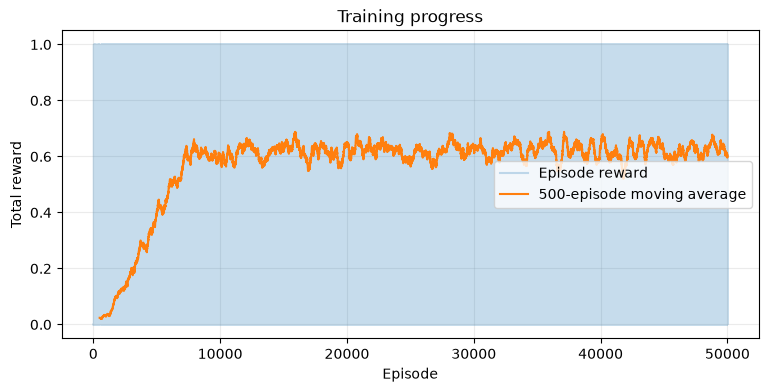

In [4]:
plt.figure(figsize=(9, 4))
plt.plot(episode_rewards, alpha=0.25, label='Episode reward')
window = 500
if len(episode_rewards) >= window:
    ma = np.convolve(episode_rewards, np.ones(window)/window, mode='valid')
    plt.plot(np.arange(window-1, len(episode_rewards)), ma, label='500-episode moving average')
plt.xlabel('Episode'); plt.ylabel('Total reward'); plt.title('Training progress')
plt.grid(alpha=0.25); plt.legend(); plt.show()

In [5]:
eval_env = gym.make('FrozenLake-v1', is_slippery=True)
success_rate, avg_length = evaluate(eval_env, agent.q_table, episodes=100)
eval_env.close()
print(f'Evaluation success rate: {success_rate:.1%}')
print(f'Average episode length: {avg_length:.2f} steps')

Evaluation success rate: 62.0%
Average episode length: 50.15 steps


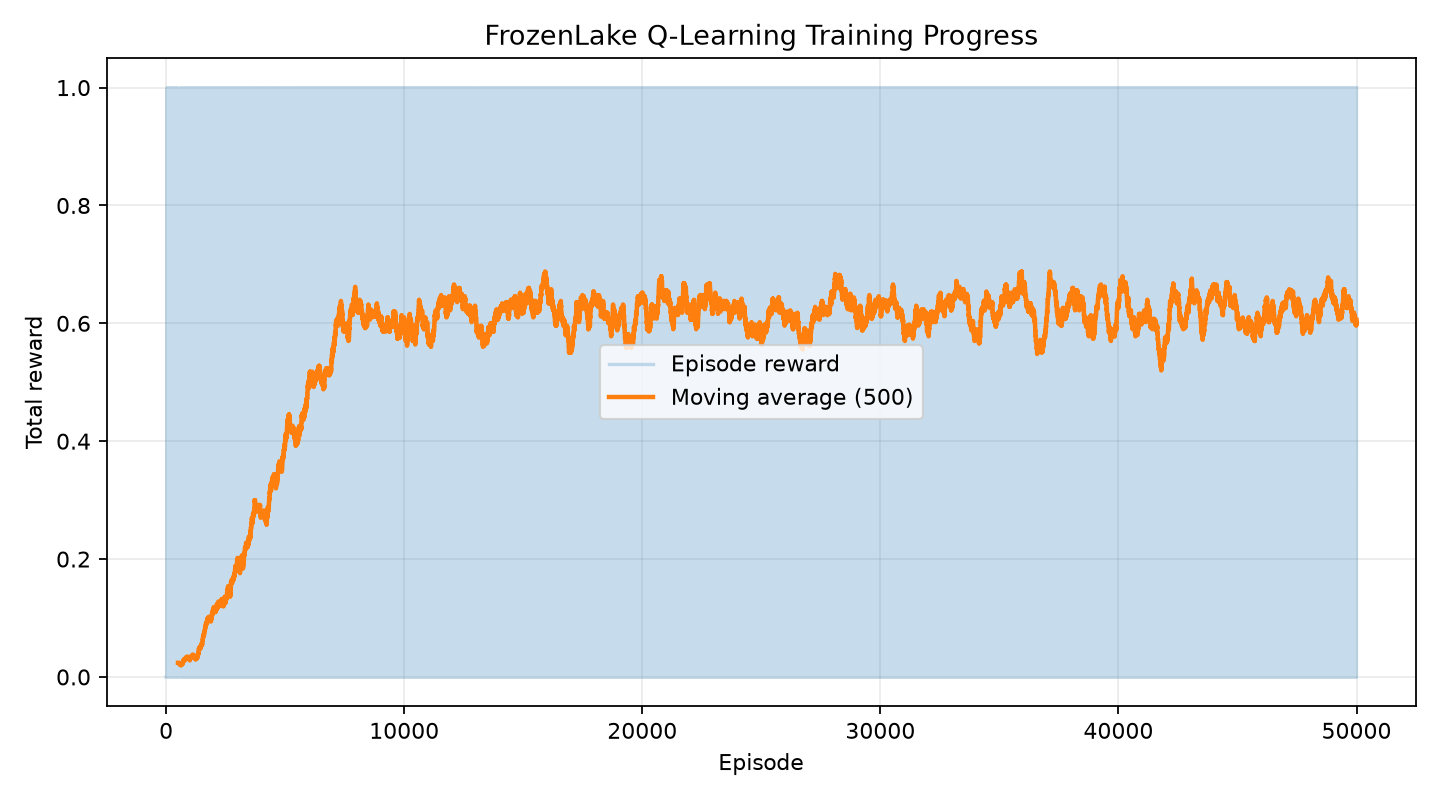

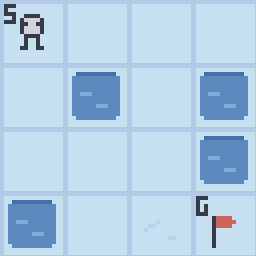

In [6]:
render_env = gym.make('FrozenLake-v1', is_slippery=True, render_mode='rgb_array')
state, _ = render_env.reset(seed=2026)
frames = [render_env.render()]
for _ in range(MAX_STEPS):
    action = int(np.argmax(agent.q_table[state]))
    state, reward, terminated, truncated, _ = render_env.step(action)
    frames.append(render_env.render())
    if terminated or truncated:
        break
render_env.close()
save_gif(frames, 'outputs/trained_agent.gif')
display(Image(filename='outputs/training_rewards.png'))
display(Image(filename='outputs/trained_agent.gif'))